# 2 eme exemple de imputation:

1- importation des bibliothèques et de donnée:

In [594]:
import pandas as pd 
import numpy as py
import matplotlib.pyplot as plt

In [595]:
df= pd.read_csv(r"C:\Users\moham\OneDrive\Desktop\Yassine\revenu_annuel.csv")

In [596]:
df

,index,Revenu_annuel
0,0,23463.404499
1,1,150506.071546
2,2,65837.284677
3,3,NaN
4,4,8481.243523
...,...,...
95,95,NaN
96,96,36983.941939
97,97,27890.709695
98,98,1287.388700


2- le nombre des valeur manquantes:

In [597]:
df.isna().sum()

index            0
Revenu_annuel    9
dtype: int64

3- pourcentages des NAN:

In [598]:
moyen_manq = df["Revenu_annuel"].isna().mean() * 100
print("Pourcentage de valeur manquante dans Revenu annuel:",moyen_manq)

Pourcentage de valeur manquante dans Revenu annuel: 9.0


In [599]:
mean_nan = df["Revenu_annuel"].isnull().sum() / len(df["Revenu_annuel"]) * 100
print("Pourcentage de valeur manquante dans Revenu annuel:", mean_nan)

Pourcentage de valeur manquante dans Revenu annuel: 9.0


alors la moyenne des valeurs manquantes est <15%

3- distribution de revenu annuel:

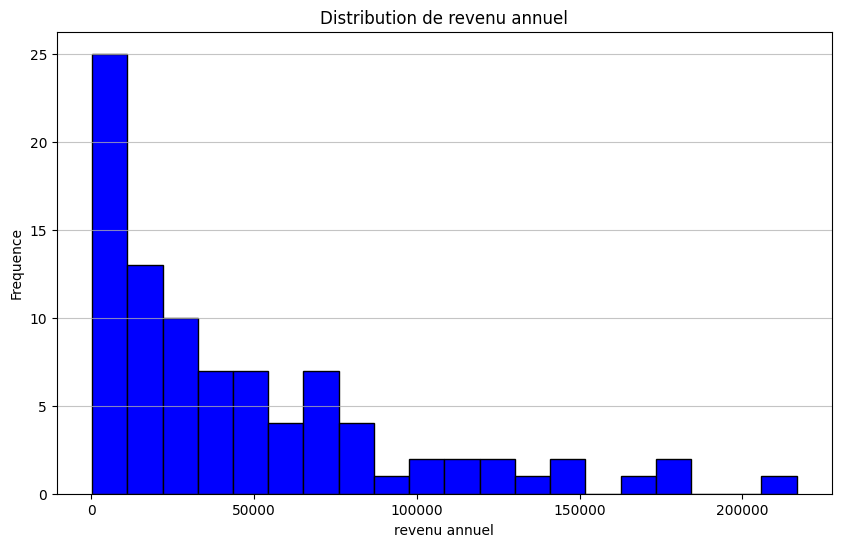

In [600]:
plt.figure(figsize=(10, 6))
plt.hist(df["Revenu_annuel"], bins= 20, color= "blue", edgecolor="black")
plt.title("Distribution de revenu annuel")
plt.xlabel("revenu annuel")
plt.ylabel("Frequence")
plt.grid(axis='y', alpha= 0.75)
plt.show()

donc l'histogrammme represente une distribution asymétrique.


4- l'imputation par la median:

In [601]:
skeweness= df["Revenu_annuel"].skew()
print("La skewness du revenu annuel est :", skeweness)

La skewness du revenu annuel est : 1.4966635722637678


la valeur de skeweness est supérieur strictment à zèro (skeweness > 0) alors est asymétrie positive.

In [602]:
median = df["Revenu_annuel"].median()
print("la médian de revenu annuel est :", median)

la médian de revenu annuel est : 29004.54212926992


5- remplassage de val_manq par la median:

In [603]:
df["Revenu_annuel"].fillna(median, inplace=True)

6- l'affichage de l'histogramme aprés l'imputation:

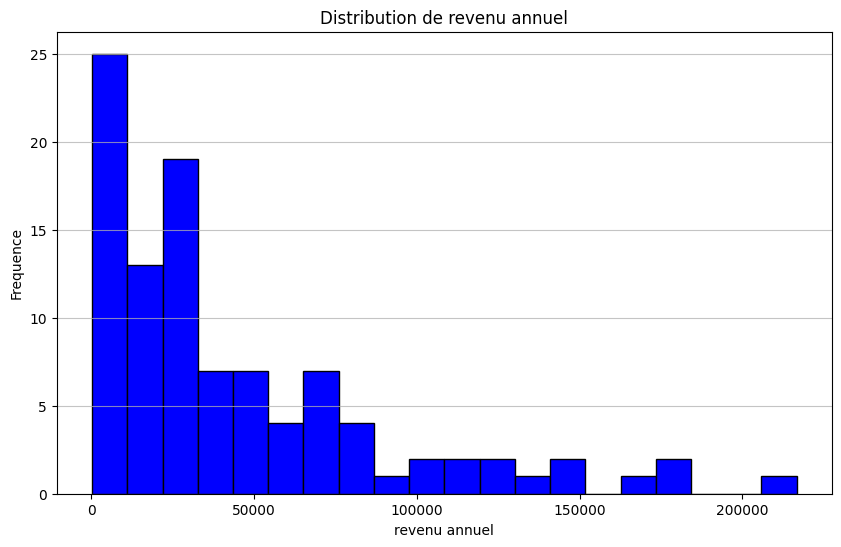

In [604]:
plt.figure(figsize=(10, 6))
plt.hist(df["Revenu_annuel"], bins= 20, color= "blue", edgecolor="black")
plt.title("Distribution de revenu annuel")
plt.xlabel("revenu annuel")
plt.ylabel("Frequence")
plt.grid(axis='y', alpha= 0.75)
plt.show()

donc la distribution reste le meme aprés le remplissage des valeurs manquantes.

In [605]:
skew_after = df["Revenu_annuel"].skew()
print("La skewness du revenu annuel après le remplissage des valeurs manquantes est :", skew_after)

La skewness du revenu annuel après le remplissage des valeurs manquantes est : 1.6382709210312731


# 3 eme exemple de imputation:

In [606]:
import pandas as pd 
import numpy as py
import matplotlib.pyplot as plt
import seaborn as sns
from   sklearn.linear_model import LinearRegression


In [607]:
data= {
      'taille': [170, 160, 180, 175, 185, 161],
      'poids': [65, 58, py.nan, 75, py.nan, 64],
      'age': [30, 25, 40, 35, 45, 26 ]
      }
df_regre= pd.DataFrame(data=data)
df_regre

,taille,poids,age
0,170,65.0,30
1,160,58.0,25
2,180,NaN,40
3,175,75.0,35
4,185,NaN,45
5,161,64.0,26


In [608]:
corr_matrix = df_regre.corr()
print("matrice de correlation: \n", corr_matrix)

matrice de correlation: 
           taille     poids       age
taille  1.000000  0.889193  0.987019
poids   0.889193  1.000000  0.946787
age     0.987019  0.946787  1.000000


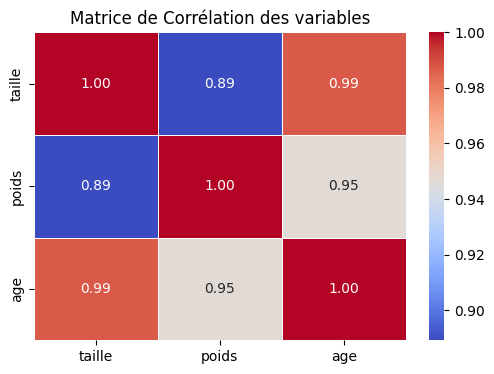

In [609]:
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Matrice de Corrélation des variables")
plt.show()

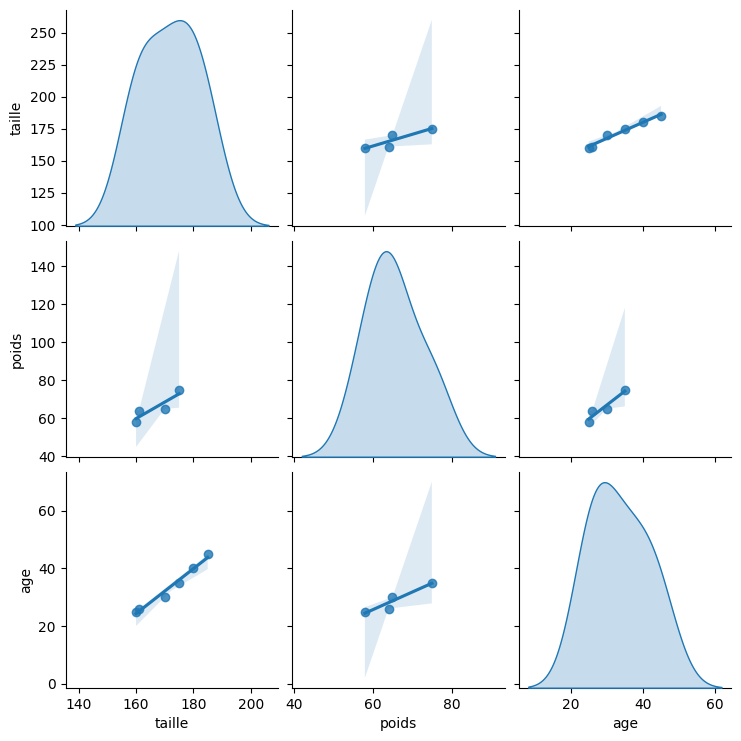

In [610]:
sns.pairplot(df_regre, kind='reg', diag_kind='kde')
plt.show()

In [611]:
train_data = df_regre[df_regre['poids'].notnull()]  
test_data = df_regre[df_regre['poids'].isnull()]  

In [612]:
X_train = train_data[['taille', 'age']] 
y_train = train_data[['poids']]  

In [613]:
model = LinearRegression()      
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [614]:
X_test = test_data[['taille', 'age']]   
predictions = model.predict(X_test) 

In [615]:
df_regre.loc[df_regre['poids'].isnull(), 'poids'] = predictions.flatten()


In [616]:

print("DataFrame après imputation par régression :\n ", df_regre)

DataFrame après imputation par régression :
     taille      poids  age
0     170  65.000000   30
1     160  58.000000   25
2     180  86.153846   40
3     175  75.000000   35
4     185  96.923077   45
5     161  64.000000   26


In [617]:
corr_matrix_after = df_regre.corr() 
print("Matrice de corrélation après imputation :\n", corr_matrix_after)

Matrice de corrélation après imputation :
           taille     poids       age
taille  1.000000  0.953625  0.987019
poids   0.953625  1.000000  0.987703
age     0.987019  0.987703  1.000000


In [618]:
train_data

,taille,poids,age
0,170,65.0,30
1,160,58.0,25
3,175,75.0,35
5,161,64.0,26


In [619]:
test_data

,taille,poids,age
2,180,NaN,40
4,185,NaN,45


# Exercice d'application p32 :

In [620]:
import pandas as pd 
import numpy as py
import matplotlib.pyplot as plt
import seaborn as sns
from   sklearn.linear_model import LinearRegression

In [621]:
donne = {
    'prix_m2': [3000.0, 3200.0, 3100.0, 3500.0, 3300.0, np.nan, 3400.0, 3700.0, np.nan],
    'age_batiment': [10.0, 15.0, 12.0, 20.0, 18.0, 25.0, np.nan, np.nan, 5.0],
    'distance_metro': [500, 700, 600, 800, 750, 900, 650, 550, 400]   
        }
df_batiment = pd.DataFrame(data=donne)
df_batiment

,prix_m2,age_batiment,distance_metro
0,3000.0,10.0,500
1,3200.0,15.0,700
2,3100.0,12.0,600
3,3500.0,20.0,800
4,3300.0,18.0,750
5,NaN,25.0,900
6,3400.0,NaN,650
7,3700.0,NaN,550
8,NaN,5.0,400


In [622]:
frequence_nan = (df_batiment.isnull().sum() / len(df_batiment)) * 100
print(frequence_nan)

prix_m2           22.222222
age_batiment      22.222222
distance_metro     0.000000
dtype: float64


Étant donné que le taux de valeurs manquantes est inférieur à $30\%$, nous pouvons procéder à une imputation par régression linéaire.

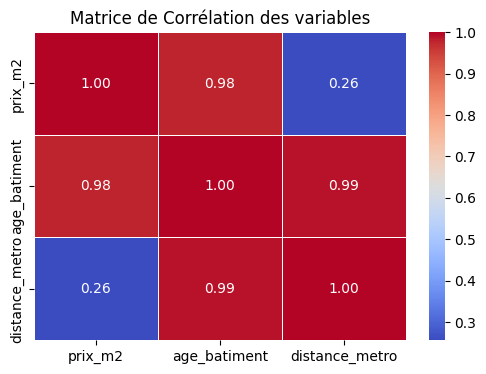

In [623]:
plt.figure(figsize=(6, 4))
sns.heatmap(df_batiment.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Matrice de Corrélation des variables")
plt.show()

D'après la matrice de corrélation, on observe une très forte relation positive entre l'âge du bâtiment et la distance au métro ($r = 0.99$). De même, une relation positive très forte est visible entre l'âge du bâtiment et le prix au $m^2$ ($r = 0.98$).

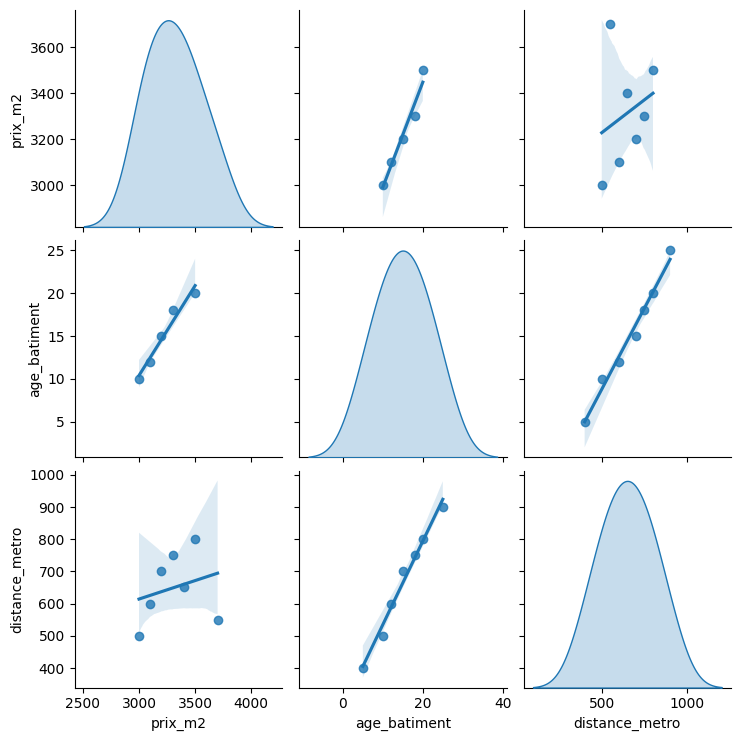

In [624]:
sns.pairplot(df_batiment, kind='reg', diag_kind='kde')
plt.show()

1. Modélisation de régression pour prédire l'âge du bâtiment à partir de la distance_metro.

In [625]:
train_data1 = df_batiment[df_batiment['age_batiment'].notnull()]  
test_data1 = df_batiment[df_batiment['age_batiment'].isnull()]  

In [626]:
X_train1 = train_data1[['distance_metro']] 
y_train1 = train_data1[['age_batiment']]  

In [627]:
X_train1

,distance_metro
0,500
1,700
2,600
3,800
4,750
5,900
8,400


In [628]:
y_train1 

,age_batiment
0,10.0
1,15.0
2,12.0
3,20.0
4,18.0
5,25.0
8,5.0


In [629]:
model_1 = LinearRegression()      
model_1.fit(X_train1, y_train1)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [630]:
X_test1 = test_data1[["distance_metro"]]   
predictions1 = model_1.predict(X_test1) 

In [631]:
df_batiment.loc[df_batiment['age_batiment'].isnull(), 'age_batiment'] = predictions1.flatten()


In [632]:
print("DataFrame après imputation par régression :\n ", df_batiment)

DataFrame après imputation par régression :
     prix_m2  age_batiment  distance_metro
0   3000.0     10.000000             500
1   3200.0     15.000000             700
2   3100.0     12.000000             600
3   3500.0     20.000000             800
4   3300.0     18.000000             750
5      NaN     25.000000             900
6   3400.0     14.459144             650
7   3700.0     10.673152             550
8      NaN      5.000000             400


2. Modélisation de régression pour prédire le prix_m2 à partir de la distance_metro et de l'âge du bâtiment.

In [633]:
train_data2 = df_batiment[df_batiment['prix_m2'].notnull()]  
test_data2 = df_batiment[df_batiment['prix_m2'].isnull()]  

In [634]:
X_train2 = train_data2[['distance_metro', 'age_batiment']] 
y_train2 = train_data2[['prix_m2']]  

In [635]:
X_train2

,distance_metro,age_batiment
0,500,10.000000
1,700,15.000000
2,600,12.000000
3,800,20.000000
4,750,18.000000
6,650,14.459144
7,550,10.673152


In [636]:
y_train2

,prix_m2
0,3000.0
1,3200.0
2,3100.0
3,3500.0
4,3300.0
6,3400.0
7,3700.0


In [637]:
model_2 = LinearRegression()      
model_2.fit(X_train2, y_train2)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [638]:
X_test2 = test_data2[["distance_metro", "age_batiment"]]   
predictions2 = model_2.predict(X_test2) 

In [639]:
df_batiment.loc[df_batiment['prix_m2'].isnull(), 'prix_m2'] = predictions2.flatten()


In [640]:
print("DataFrame après imputation par régression :\n ", df_batiment)

DataFrame après imputation par régression :
         prix_m2  age_batiment  distance_metro
0  3000.000000     10.000000             500
1  3200.000000     15.000000             700
2  3100.000000     12.000000             600
3  3500.000000     20.000000             800
4  3300.000000     18.000000             750
5  3477.196327     25.000000             900
6  3400.000000     14.459144             650
7  3700.000000     10.673152             550
8  3164.134662      5.000000             400


In [641]:
df_batiment.to_csv("batiment.csv")